# StudyGuard: model, explanations and evaluation

Run from the repo root or the `python/` folder: `jupyter notebook python/studyguard_analysis.ipynb`.
Needs `pip install -r python/requirements.txt` plus `jupyter`. Run the cells top to bottom.

**Question.** Can a small, fully transparent classifier tell prompts that ask for finished work
(HOLD) from prompts that show effort (PASS), and can we explain each decision faithfully?

**Contents:** 1 data, 2 why random cross-validation misleads, 3 what the model learned,
4 SHAP (exact), 5 LIME, 6 held-out results, 7 calibration, 8 takeaways.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "eval").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "python"))

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import Image, display

import make_figures as mf
import explain_shap_lime as ex
from studyguard_features import pack
print("Repo root:", ROOT)

Repo root: /Users/eugeniatate/Code/XAI/StudyGuard


## 1. Training data
400 synthetic prompts (200 HOLD, 200 PASS) from templates, in eight categories. The dev and held-out
sets are never used for training.

In [2]:
rows, texts, y, groups = mf.load_training()
counts = Counter((r["category"], r["label"]) for r in rows)
for (cat, label), n in sorted(counts.items()):
    print(f"{cat:18s} {label}  {n}")
print("\nExample rows:")
for r in rows[:6]:
    print(f"  [{r['label']}] {r['prompt']}")

answer_request     HOLD  45
attempt_shown      PASS  50
code_request       HOLD  80
conceptual         PASS  55
essay_request      HOLD  45
feedback_request   PASS  50
hint_request       PASS  45
terse_request      HOLD  30

Example rows:
  [PASS] Quiz me on closures
  [HOLD] Answer this probability question for me
  [HOLD] Implement a CSV parser in Go for me
  [HOLD] i need the code for binary search, just the code no explanation
  [HOLD] Could you please just solve exercise 2.4 step by step so I can copy it
  [PASS] What sources should I look for on photosynthesis?


## 2. Why random cross-validation misleads
Ordinary k-fold cross-validation puts prompts from the same templates in both train and test folds, so it
rewards memorising templates. Holding out a whole *category* tests generalisation to a new kind of prompt.

Wrote docs/figures/cv_comparison.png


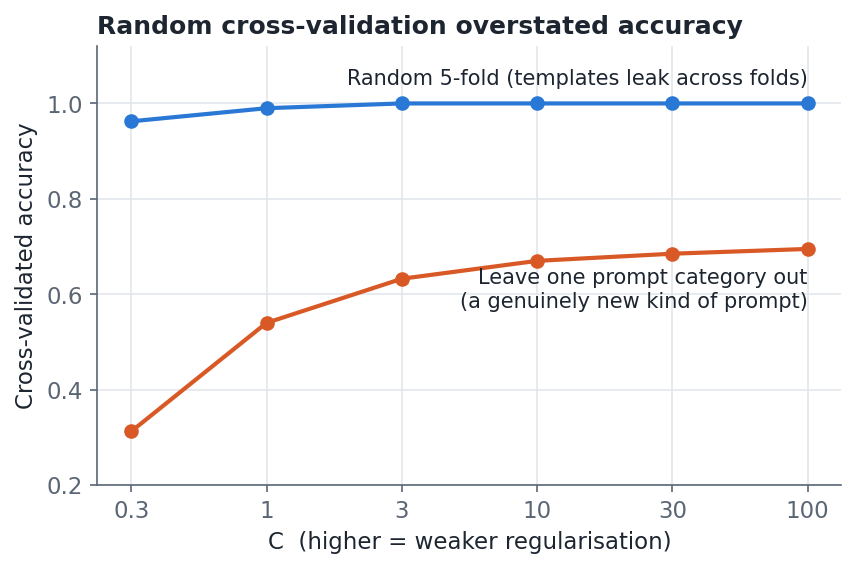

In [3]:
mf.cv_comparison(texts, y, groups)
display(Image(str(ROOT / "docs/figures/cv_comparison.png")))

## 3. What the model learned
A TF-IDF + logistic regression model has one weight per word or word pair. Positive = toward HOLD.

In [4]:
C = json.load(open(ROOT / "model/model.sklearn.json"))["options"]["C"]
vec, clf = mf.fit(texts, y, C)
terms = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])
pick = np.r_[order[:12], order[-12:]]
fig, ax = plt.subplots(figsize=(6, 6))
ax.barh(terms[pick], clf.coef_[0][pick], color=[mf.ORANGE if w > 0 else mf.BLUE for w in clf.coef_[0][pick]], height=0.65)
ax.axvline(0, color=mf.MUTED, lw=1); ax.set_xlabel("weight (log-odds): right = HOLD, left = PASS")
ax.set_title("Strongest learned weights", loc="left", fontweight="bold"); plt.show()

/var/folders/5x/q5fbgxg15935m9y58fcbmnbr0000gn/T/ipykernel_92480/1597190978.py:9: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  ax.set_title("Strongest learned weights", loc="left", fontweight="bold"); plt.show()


## 4. SHAP: exact for a linear model
For a linear model SHAP has a closed form, `w_i * (x_i - mean_i)`. We check that the `shap` library
gives the same numbers. (`shap` keeps only 100 background rows by default, which changes the mean;
we pass all rows.)

In [5]:
import shap
X = vec.transform(texts); Xd = X.toarray(); mean = Xd.mean(axis=0)
prompt = "Could you please put together a complete solution for my sorting assignment?"
x = vec.transform([pack(prompt)]).toarray()
phi = ex.shap_feature_values(shap, clf, Xd, x)
print("max |shap - closed form| =", float(np.max(np.abs(phi - ex.closed_form_shap(clf, mean, x)))))
print("p(HOLD) =", round(ex.p_hold(vec, clf, prompt), 3))
words, vals = ex.shap_per_occurrence(prompt, list(terms), phi)
for w, v in sorted(zip(words, vals), key=lambda t: -abs(t[1]))[:8]:
    print(f"  {w:12s} {v:+.2f}")

max |shap - closed form| = 0.0
p(HOLD) = 0.931
  please       +0.50
  complete     +0.41
  solution     +0.24
  put          +0.22
  together     +0.22
  a            +0.20
  my           -0.17
  assignment   +0.15


Wrote docs/figures/shap_examples.png


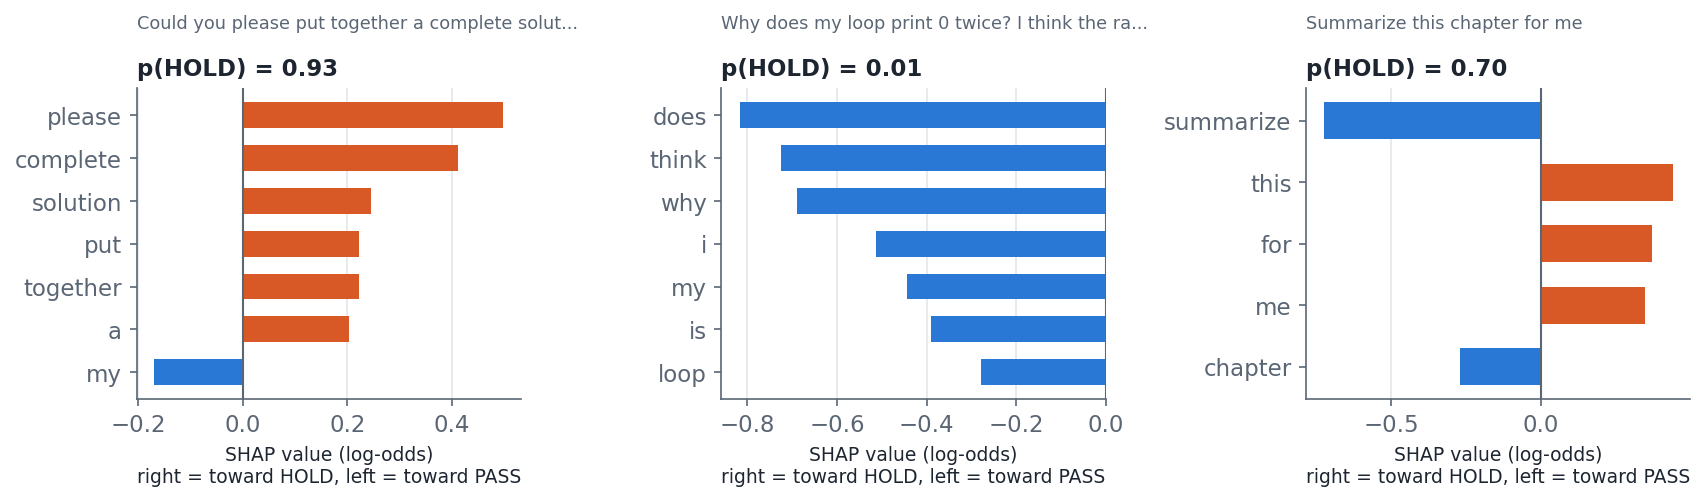

In [6]:
mf.shap_examples(vec, clf, X)
display(Image(str(ROOT / "docs/figures/shap_examples.png")))

## 5. LIME
LIME perturbs the prompt (drops random words), watches the model, and fits a small local linear model.
Unlike SHAP it is random, so we check stability across seeds.

In [7]:
from lime import lime_text
l1 = ex.lime_values(lime_text, vec, clf, prompt, seed=1)
l2 = ex.lime_values(lime_text, vec, clf, prompt, seed=2)
occ = ex.occlusion_values(vec, clf, prompt)
print(f"{'word':12s} {'LIME s1':>8s} {'LIME s2':>8s} {'occlusion':>10s}")
for w in sorted(l1, key=lambda k: -abs(l1[k]))[:8]:
    print(f"{w:12s} {l1[w]:8.3f} {l2.get(w, 0):8.3f} {occ.get(w, 0):10.3f}")

word          LIME s1  LIME s2  occlusion
please          0.075    0.076      0.042
complete        0.054    0.061      0.031
my             -0.047   -0.053     -0.017
a               0.036    0.039      0.020
solution        0.033    0.038      0.016
assignment      0.020    0.020      0.006
could          -0.013   -0.010     -0.004
together        0.010    0.010      0.003


## 6. Held-out results
Rules v1, rules v2 and the trained model on the 40 held-out prompts (labelled blind; UNSURE excluded).
Run `node eval/export_predictions.js` first.

Wrote docs/figures/confusion_heldout.png


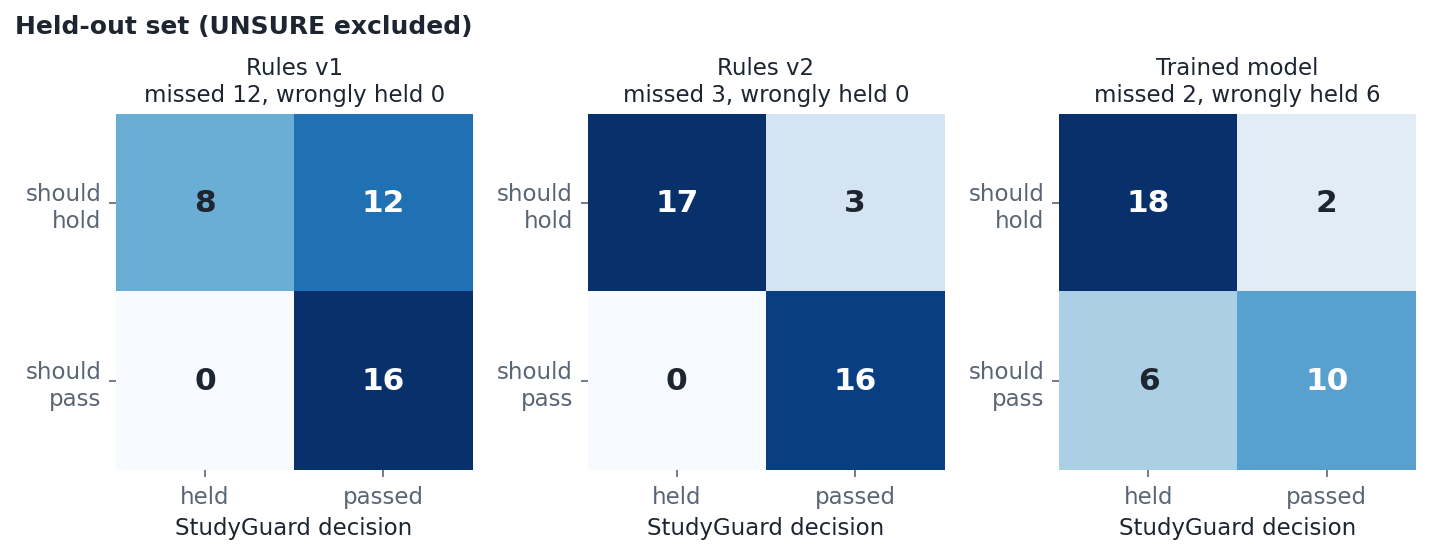

In [8]:
mf.confusion_heldout(vec, clf)
display(Image(str(ROOT / "docs/figures/confusion_heldout.png")))

## 7. Calibration
Does a model score of 0.7 mean about 70% of such prompts really should be held? Points near the dashed line
mean yes. The sets are small, so each bin is noisy.

Wrote docs/figures/reliability.png


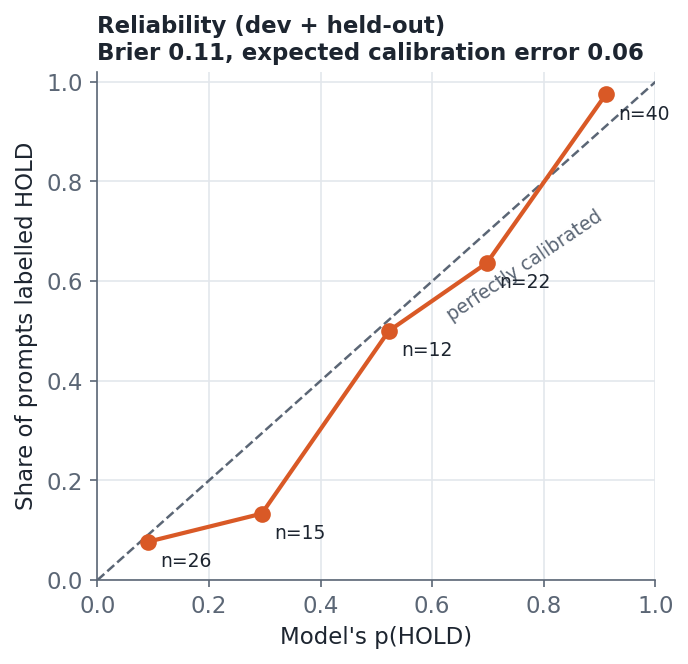

In [9]:
mf.reliability(vec, clf)
display(Image(str(ROOT / "docs/figures/reliability.png")))

## 8. Takeaways
* Rules v2 gave the best held-out accuracy and never held an honest prompt; the model found slightly more
  answer-seeking prompts but wrongly held many honest ones.
* Random cross-validation hid how much the model memorised templates; category-held-out validation did not.
* SHAP, LIME and occlusion agree closely on a linear model, which is the point of using a glass-box model.
* Limits: small labelled sets, one annotator, synthetic training data, no user study.